# Cash Flow Copilot — Step 2: Late-Invoice Prediction
**المهمة:** وقت إصدار الفاتورة، نتنبأ هل هتتأخر (`is_late`) وبكام يوم (`payment_delay_days`).

**القاعدة الأساسية:** أي feature لازم يكون معروف *وقت إصدار الفاتورة*. تاريخ العميل بنستخدم منه بس الفواتير اللي اتدفعت فعلاً قبل تاريخ الفاتورة الحالية.

In [4]:
pip install lightgbm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, f1_score, precision_score, recall_score, mean_absolute_error
import lightgbm as lgb
sns.set_theme(style="whitegrid")

DATA_DIR = "data"
inv = pd.read_csv(f"{DATA_DIR}/synthetic_sme_invoices.csv", parse_dates=["invoice_date","due_date","paid_date"])
cf  = pd.read_csv(f"{DATA_DIR}/synthetic_sme_daily_cash_flow.csv", parse_dates=["date"])

# 1) استبعد الفواتير outstanding (النتيجة بتاعتها مش معروفة / فيها leakage من المستقبل)
print("Outstanding excluded:", (inv.status != "paid").sum())
df = inv[inv.status == "paid"].copy().sort_values("invoice_date").reset_index(drop=True)
print("Invoices used:", len(df), "| late rate:", df.is_late.mean().round(3))

Outstanding excluded: 294
Invoices used: 8474 | late rate: 0.189


## 1) Feature engineering (بدون leakage)

In [6]:
df["terms_days"] = (df.due_date - df.invoice_date).dt.days
df["month"] = df.invoice_date.dt.month
df["dow"] = df.invoice_date.dt.dayofweek
df["due_dow"] = df.due_date.dt.dayofweek
df["log_amount"] = np.log1p(df.invoice_amount_egp)

# sector + promo flag يوم إصدار الفاتورة
meta = cf[["date","business_id","sector","promotion_flag"]].rename(columns={"date":"invoice_date"})
df = df.merge(meta, on=["business_id","invoice_date"], how="left")

# --- history features: فقط فواتير اتدفعت (paid_date) قبل تاريخ الفاتورة الحالية ---
GLOBAL = df.is_late.mean(); K = 5   # smoothing للعملاء الجداد
def add_history(df, key, prefix):
    rows = []
    for _, g in df.groupby(key):
        g = g.sort_values("invoice_date")
        inv_d = g.invoice_date.values; paid_d = g.paid_date.values
        late = g.is_late.values; delay = g.payment_delay_days.values; amt = g.invoice_amount_egp.values
        for i in range(len(g)):
            m = paid_d < inv_d[i]            # اتدفعت قبل ما الفاتورة دي تتصدر
            n = m.sum()
            rows.append((g.index[i], n,
                         (late[m].sum() + K*GLOBAL) / (n + K),
                         delay[m].mean() if n else np.nan,
                         amt[m].mean() if n else np.nan))
    h = pd.DataFrame(rows, columns=["idx", f"{prefix}_n", f"{prefix}_late_rate", f"{prefix}_avg_delay", f"{prefix}_avg_amt"]).set_index("idx")
    return df.join(h)

df = add_history(df, ["business_id","customer_id"], "cust")
df = add_history(df, ["business_id"], "biz")
df["amt_vs_cust_avg"] = df.invoice_amount_egp / df.cust_avg_amt
df[["cust_n","cust_late_rate","cust_avg_delay","amt_vs_cust_avg"]].describe().round(2)

,cust_n,cust_late_rate,cust_avg_delay,amt_vs_cust_avg
count,8474.00,8474.00,7029.00,7029.00
mean,3.30,0.19,3.47,1.13
std,2.71,0.07,6.60,0.57
min,0.00,0.05,0.00,0.14
25%,1.00,0.13,0.00,0.75
50%,3.00,0.18,0.00,1.03
75%,5.00,0.22,4.67,1.40
max,14.00,0.54,60.00,9.67


## 2) Time-based split (نفس الـ split بتاع Step 1)

In [7]:
def split(d): return np.where(d <= "2024-12-31", "train", np.where(d <= "2025-06-30", "val", "test"))
df["split"] = split(df.invoice_date)
print(df.groupby("split").is_late.agg(["size","mean"]).round(3))

CAT = ["business_id","sector"]
df["long_terms"] = (df.terms_days >= 45).astype(int)
NUM_LEAN = ["log_amount","terms_days","long_terms"]
NUM = ["log_amount","terms_days","month","dow","due_dow","promotion_flag",
       "cust_n","cust_late_rate","cust_avg_delay","amt_vs_cust_avg",
       "biz_late_rate","biz_avg_delay"]
for c in CAT: df[c] = df[c].astype("category")
tr, va, te = (df[df.split==s] for s in ["train","val","test"])
y = "is_late"

       size   mean
split             
test   1178  0.163
train  5848  0.188
val    1448  0.213


## 2b) هل فيه signal حقيقي؟ (اختبارات إحصائية قبل الموديلات)

In [8]:
from scipy.stats import chi2_contingency
d = df.copy(); d["terms_days"] = d.terms_days.astype(int)
rows = []
for c in ["customer_id","terms_days","business_id","sector","month","promotion_flag"]:
    p = chi2_contingency(pd.crosstab(d[c], d.is_late))[1]; rows.append((c, p, "REAL" if p < 0.01 else "noise"))
print(pd.DataFrame(rows, columns=["feature","chi2_p_value","verdict"]).round(4).to_string(index=False))

g = d.groupby("customer_id").is_late.agg(["mean","size"])
print("\nCustomer late-rate std observed:", g["mean"].std().round(3),
      "| expected from pure binomial noise:", np.sqrt(d.is_late.mean()*(1-d.is_late.mean())/g["size"]).mean().round(3))
print("\nLate rate by terms:"); print(d.groupby("terms_days").is_late.mean().round(3).to_dict())

       feature  chi2_p_value verdict
   customer_id        0.6128   noise
    terms_days        0.0000    REAL
   business_id        0.0052    REAL
        sector        0.0009    REAL
         month        0.2115   noise
promotion_flag        0.8991   noise

Customer late-rate std observed: 0.051 | expected from pure binomial noise: 0.052

Late rate by terms:
{7: 0.145, 14: 0.147, 30: 0.16, 45: 0.266, 60: 0.27}


## 3) Models: Baseline → Logistic Regression → LightGBM

In [9]:
def report(name, y_true, p, thr=None):
    roc, pr = roc_auc_score(y_true, p), average_precision_score(y_true, p)
    out = {"model": name, "ROC-AUC": round(roc,3), "PR-AUC": round(pr,3)}
    if thr is not None:
        yh = (p >= thr).astype(int)
        out.update({"thr": round(thr,3), "precision": round(precision_score(y_true,yh),3),
                    "recall": round(recall_score(y_true,yh),3), "F1": round(f1_score(y_true,yh),3)})
    return out

def best_thr(y_true, p):               # threshold بيتحدد على val بس
    pr, rc, th = precision_recall_curve(y_true, p)
    f1 = 2*pr*rc/(pr+rc+1e-9); return th[np.argmax(f1[:-1])]

results, probs = [], {}

# (0) Baseline: نسبة تأخر العميل التاريخية
p_va, p_te = va.cust_late_rate.values, te.cust_late_rate.values
t = best_thr(va[y], p_va); probs["Baseline"] = p_te
results.append(report("Baseline (customer history)", te[y], p_te, t))

# (1) Logistic Regression
X = lambda d: pd.get_dummies(d[NUM+CAT], columns=CAT).fillna(d[NUM].median(numeric_only=True)).astype(float)
Xtr, Xva, Xte = X(tr), X(va).reindex(columns=X(tr).columns, fill_value=0), X(te).reindex(columns=X(tr).columns, fill_value=0)
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")).fit(Xtr, tr[y])
t = best_thr(va[y], lr.predict_proba(Xva)[:,1]); probs["LogReg"] = lr.predict_proba(Xte)[:,1]
results.append(report("Logistic Regression", te[y], probs["LogReg"], t))

# (2) LightGBM
params = dict(n_estimators=400, learning_rate=0.03, num_leaves=15, min_child_samples=40,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=2.0, random_state=42, verbose=-1)
gbm = lgb.LGBMClassifier(**params)
gbm.fit(tr[NUM+CAT], tr[y], eval_set=[(va[NUM+CAT], va[y])], eval_metric="auc",
        callbacks=[lgb.early_stopping(50, verbose=False)])
print("best iteration:", gbm.best_iteration_)
t = best_thr(va[y], gbm.predict_proba(va[NUM+CAT])[:,1]); probs["LightGBM"] = gbm.predict_proba(te[NUM+CAT])[:,1]
results.append(report("LightGBM", te[y], probs["LightGBM"], t))

pd.DataFrame(results).set_index("model")

c:\Users\Pc\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


best iteration: 7


,ROC-AUC,PR-AUC,thr,precision,recall,F1
model,,,,,,
Baseline (customer history),0.515,0.180,0.059,0.163,1.000,0.281
Logistic Regression,0.603,0.257,0.407,0.171,0.818,0.283
LightGBM,0.597,0.225,0.181,0.191,0.672,0.297


## 3b) Ablation: هل الـ customer-history features بتفيد فعلاً؟

In [10]:
def run_gbm(num, cat, label):
    m = lgb.LGBMClassifier(**{**params, "n_estimators": 300})
    m.fit(tr[num+cat], tr[y], eval_set=[(va[num+cat], va[y])], eval_metric="auc", callbacks=[lgb.early_stopping(50, verbose=False)])
    p = m.predict_proba(te[num+cat])[:,1]
    return {"features": label, "ROC-AUC": round(roc_auc_score(te[y], p),3), "PR-AUC": round(average_precision_score(te[y], p),3), "iters": m.best_iteration_}, m, p
HIST = ["cust_n","cust_late_rate","cust_avg_delay","amt_vs_cust_avg","biz_late_rate","biz_avg_delay"]
abl = []
for label, num, cat in [("ALL (incl. customer history)", NUM, CAT),
                        ("No customer history", [c for c in NUM if c not in HIST], CAT),
                        ("LEAN: amount + terms + business/sector", NUM_LEAN, CAT),
                        ("Terms only", ["terms_days","long_terms"], [])]:
    r, m, p = run_gbm(num, cat, label); abl.append(r)
    if label.startswith("LEAN"): gbm_lean, p_lean = m, p
pd.DataFrame(abl).set_index("features")

c:\Users\Pc\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Pc\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Pc\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Pc\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'ev

,ROC-AUC,PR-AUC,iters
features,,,
ALL (incl. customer history),0.597,0.225,7
No customer history,0.610,0.252,29
LEAN: amount + terms + business/sector,0.619,0.241,55
Terms only,0.610,0.223,1


## 4) Curves & feature importance

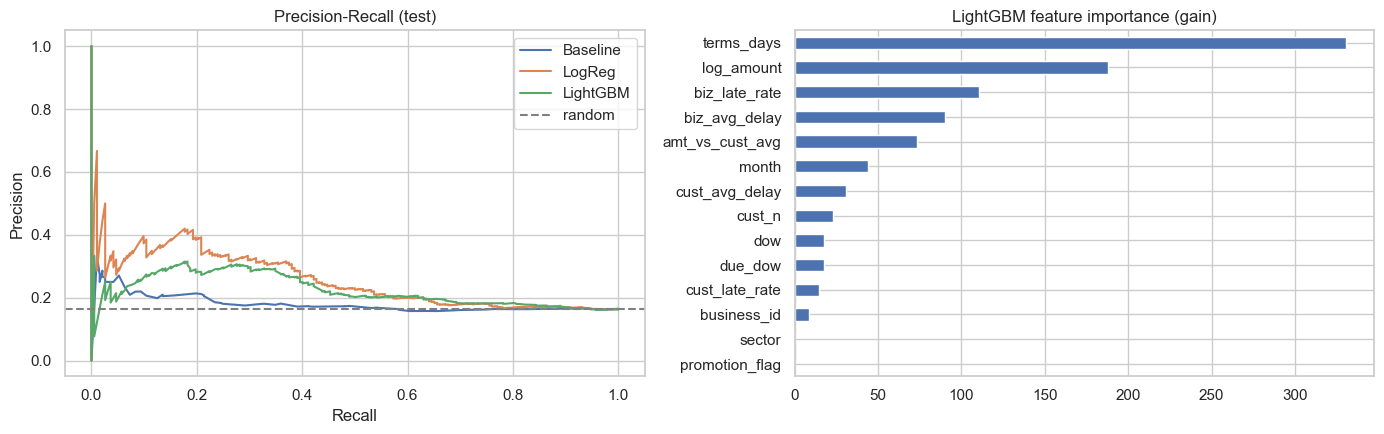

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(14,4.5))
for n, p in probs.items():
    pr, rc, _ = precision_recall_curve(te[y], p); axs[0].plot(rc, pr, label=n)
axs[0].axhline(te[y].mean(), ls="--", c="gray", label="random"); axs[0].set_xlabel("Recall"); axs[0].set_ylabel("Precision"); axs[0].set_title("Precision-Recall (test)"); axs[0].legend()
imp = pd.Series(gbm.booster_.feature_importance("gain"), index=NUM+CAT).sort_values()
imp.plot.barh(ax=axs[1], title="LightGBM feature importance (gain)"); plt.tight_layout(); plt.show()

## 5) Delay-days regression (للـ cash forecasting في Step 3)\nبنتنبأ بعدد أيام التأخير لكل فاتورة (0 لو مش متأخرة) — هنحتاجه عشان نحدد *امتى* الفلوس هتدخل.

In [12]:
tgt = "payment_delay_days"
base_mae = mean_absolute_error(te[tgt], np.full(len(te), tr[tgt].mean()))
cust_mae = mean_absolute_error(te[tgt], te.cust_avg_delay.fillna(tr[tgt].mean()))
reg = lgb.LGBMRegressor(**{**params, "objective":"regression_l1"})
reg.fit(tr[NUM+CAT], tr[tgt], eval_set=[(va[NUM+CAT], va[tgt])], callbacks=[lgb.early_stopping(50, verbose=False)])
reg_mae = mean_absolute_error(te[tgt], reg.predict(te[NUM+CAT]))
zero_mae = mean_absolute_error(te[tgt], np.zeros(len(te)))
print(f"MAE (days) | always-0: {zero_mae:.2f} | global mean: {base_mae:.2f} | customer avg: {cust_mae:.2f} | LightGBM(L1): {reg_mae:.2f}")
print("=> الـ L1 regressor بيتنبأ تقريباً بـ 0 (الـ median)، يعني مفيش مكسب حقيقي عن baseline 'صفر'. الأفضل: expected delay = P(late) x متوسط تأخر الفواتير المتأخرة.")
late_avg = tr.loc[tr.is_late==1, tgt].mean(); print("avg delay when late (train):", round(late_avg,1), "days")

MAE (days) | always-0: 2.68 | global mean: 5.32 | customer avg: 5.36 | LightGBM(L1): 2.68
=> الـ L1 regressor بيتنبأ تقريباً بـ 0 (الـ median)، يعني مفيش مكسب حقيقي عن baseline 'صفر'. الأفضل: expected delay = P(late) x متوسط تأخر الفواتير المتأخرة.
avg delay when late (train): 20.5 days


c:\Users\Pc\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


## 6) Error analysis: مين الفواتير اللي بنغلط فيها؟

In [13]:
te = te.assign(p=p_lean)
te["risk"] = pd.qcut(te.p, 5, labels=["Q1 low","Q2","Q3","Q4","Q5 high"])
print(te.groupby("risk", observed=True).agg(n=("is_late","size"), late_rate=("is_late","mean"), amount_egp=("invoice_amount_egp","sum")).round(3))
print("\nTop-20% riskiest invoices capture", round(te[te.risk=="Q5 high"].is_late.sum()/te.is_late.sum()*100,1), "% of all late invoices")

           n  late_rate  amount_egp
risk                               
Q1 low   237      0.105   534020.01
Q2       235      0.145   777807.68
Q3       235      0.132  1253331.63
Q4       235      0.119  1422849.09
Q5 high  236      0.314  1283802.76

Top-20% riskiest invoices capture 38.5 % of all late invoices


## 7) Save model & predictions

In [14]:
import joblib, os; os.makedirs("models", exist_ok=True); os.makedirs("processed", exist_ok=True)
joblib.dump({"clf": gbm_lean, "reg": reg, "features": NUM_LEAN+CAT, "reg_features": NUM+CAT}, "models/late_invoice_models.joblib")
te[["invoice_id","business_id","customer_id","invoice_date","invoice_amount_egp","is_late","payment_delay_days","p"]].to_csv("processed/test_predictions.csv", index=False)
print("saved")

saved
